# Kumo Tabular vs. Optuna-tuned LightGBM — credit card fraud

NVIDIA's tabular foundation model **Kumo Tabular** (in-context learning, no training, no tuning) against **LightGBM tuned with Optuna** on [Kaggle Playground S6E11 · Predicting Credit Card Fraud](https://www.kaggle.com/competitions/playground-series-s6e11): 700k transactions, 1.7 % fraud, metric ROC-AUC.

Protocol (`run_oof.py`): stratified 5-fold over all training rows. In each fold every model learns from N rows of the other folds and predicts the full held-out fold (~140k rows). Optuna tunes LightGBM on those N rows only (nested CV). This notebook only analyses the saved out-of-fold predictions.

In [ ]:
import sys, json
sys.path.append("..")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_curve, precision_recall_curve

from kumo_fraud.metrics import scores, reliability

RES = Path("../results")
ID, TARGET = "id", "is_fraud"
NAMES = {"logreg": "Logistic regression", "lgb_default": "LightGBM (default)",
         "lgb_optuna": "LightGBM (Optuna)", "kumo": "Kumo Tabular"}

oof = {p.name.removesuffix(".csv.gz"): pd.read_csv(p) for p in sorted((RES / "oof").glob("*.csv.gz"))}
timings = pd.read_csv(RES / "timings.csv").drop_duplicates(["n", "fold", "model"], keep="last")
params = json.loads((RES / "params.json").read_text())
model_cols = lambda df: [c for c in df.columns if c not in (ID, "fold", TARGET)]
print({k: (len(v), model_cols(v)) for k, v in oof.items()})

{'full': (699960, ['lgb_optuna', 'kumo']), 'n1000': (699960, ['logreg', 'lgb_default', 'lgb_optuna', 'kumo']), 'n16000': (699960, ['logreg', 'lgb_default', 'lgb_optuna', 'kumo', 'kumo_pos0.05', 'kumo_pos0.10', 'kumo_pos0.25']), 'n4000': (699960, ['logreg', 'lgb_default', 'lgb_optuna', 'kumo']), 'n64000': (699960, ['logreg', 'lgb_default', 'lgb_optuna', 'kumo'])}


In [ ]:
# Per-fold scores for every setting x model
rows = []
for tag, df in oof.items():
    for m in model_cols(df):
        for k, g in df.groupby("fold"):
            rows.append({"setting": tag, "model": m, "fold": k,
                         **scores(g[TARGET].to_numpy(), g[m].to_numpy())})
per_fold = pd.DataFrame(rows)
per_fold = per_fold.merge(timings.rename(columns={"n": "setting"}), on=["setting", "fold", "model"], how="left")
n_of = lambda t: np.inf if t == "full" else int(t[1:])
per_fold["n"] = per_fold["setting"].map(n_of)
per_fold.to_csv(RES / "per_fold_scores.csv", index=False)

summary = (per_fold.groupby(["n", "model"])
           .agg(AUC=("ROC_AUC", "mean"), AUC_sd=("ROC_AUC", "std"),
                PR_AUC=("PR_AUC", "mean"), recall_1pct=("recall@1%FPR", "mean"),
                seconds=("seconds", "mean")))
summary.round(4)

AUC  AUC_sd  PR_AUC  recall_1pct    seconds
n       model                                                       
1000.0  kumo          0.9104  0.0049  0.3299       0.3668    50.1697
        lgb_default   0.8679  0.0145  0.1991       0.2385     0.2223
        lgb_optuna    0.8851  0.0166  0.2571       0.2944    22.2131
        logreg        0.8893  0.0124  0.2985       0.3338     0.2258
4000.0  kumo          0.9342  0.0031  0.4440       0.4641    61.9189
        lgb_default   0.9005  0.0096  0.3162       0.3663     0.2259
        lgb_optuna    0.9202  0.0034  0.3572       0.3986    36.6516
        logreg        0.9216  0.0025  0.4076       0.4295     0.2241
16000.0 kumo          0.9404  0.0018  0.4806       0.4935   114.3303
        kumo_pos0.05  0.9429  0.0017  0.4909       0.5047   116.0922
        kumo_pos0.10  0.9440  0.0017  0.4963       0.5065   116.2829
        kumo_pos0.25  0.9452  0.0019  0.5017       0.5120   116.2691
        lgb_default   0.9221  0.0023  0.3787       0.4100     0.2745
        lgb_optuna    0.9350  0.0009  0.4436       0.4626    74.0585
        logreg        0.9367  0.0019  0.4683       0.4819     0.8668
64000.0 kumo          0.9430  0.0019  0.4934       0.5041   397.0406
        lgb_default   0.9320  0.0020  0.4213       0.4393     0.3262
        lgb_optuna    0.9421  0.0023  0.4851       0.4995   204.7574
        logreg        0.9403  0.0019  0.4835       0.4952     0.8374
inf     kumo          0.9428  0.0016  0.4920       0.5022   790.0991
        lgb_optuna    0.9475  0.0022  0.5146       0.5237  1111.6186

## 1 · Is the gap real? Paired comparison over folds

Same fold, same N, same held-out rows, so the per-fold difference is a paired sample.

In [ ]:
def paired(a, b):
    out = []
    for n, g in per_fold.groupby("n"):
        w = g.pivot(index="fold", columns="model", values="ROC_AUC")
        if {a, b} <= set(w.columns):
            d = w[a] - w[b]
            t = stats.ttest_rel(w[a], w[b]) if len(d) > 1 else None
            out.append({"n": n, "mean_diff": d.mean(), "sd": d.std(),
                        "folds_a_better": int((d > 0).sum()), "folds": len(d),
                        "p (paired t)": t.pvalue if t else np.nan})
    return pd.DataFrame(out).set_index("n")

print("Kumo − LightGBM (Optuna), ROC-AUC")
paired("kumo", "lgb_optuna").round(5)

Kumo − LightGBM (Optuna), ROC-AUC


,mean_diff,sd,folds_a_better,folds,p (paired t)
n,,,,,
1000.0,0.02536,0.01581,5,5,0.02300
4000.0,0.01394,0.00172,5,5,0.00005
16000.0,0.00548,0.00115,5,5,0.00044
64000.0,0.00092,0.00107,3,5,0.12757
inf,-0.00462,0.00065,0,5,0.00009


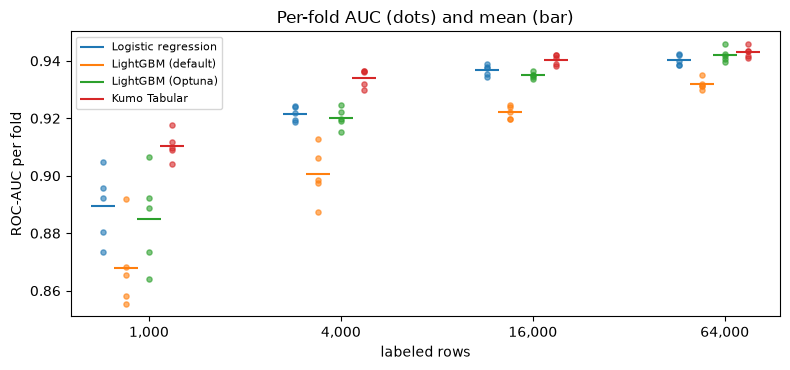

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sizes = sorted(n for n in per_fold.n.unique() if np.isfinite(n))
models = [m for m in NAMES if m in per_fold.model.unique()]
for i, m in enumerate(models):
    g = per_fold[(per_fold.model == m) & per_fold.n.isin(sizes)]
    x = np.array([sizes.index(n) for n in g.n]) + (i - len(models) / 2) * 0.12
    ax.scatter(x, g.ROC_AUC, s=14, alpha=0.6, color=f"C{i}")
    agg = g.groupby("n").ROC_AUC.mean()
    ax.scatter(np.arange(len(sizes)) + (i - len(models) / 2) * 0.12, agg.values, marker="_", s=300,
               color=f"C{i}", label=NAMES[m])
ax.set_xticks(range(len(sizes)), [f"{int(n):,}" for n in sizes])
ax.set(xlabel="labeled rows", ylabel="ROC-AUC per fold", title="Per-fold AUC (dots) and mean (bar)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(RES / "per_fold_auc.png", dpi=150)

## 2 · Learning curve and cost

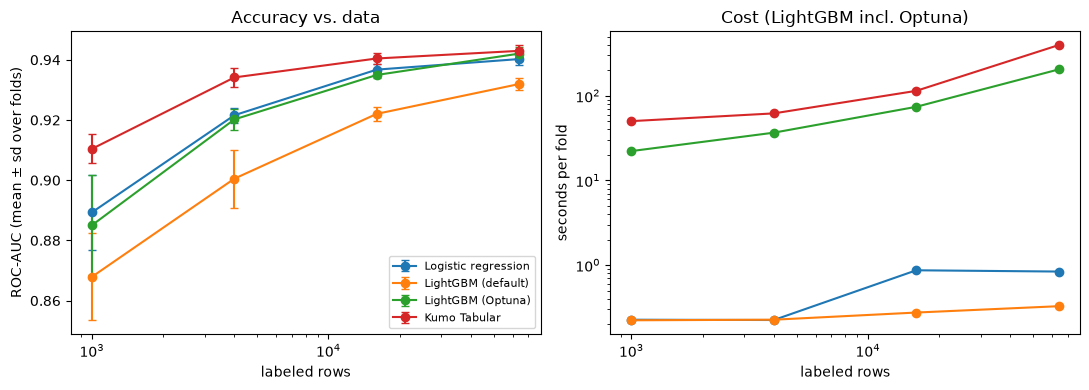

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m in models:
    g = summary.xs(m, level="model")
    g = g[np.isfinite(g.index)]
    ax[0].errorbar(g.index, g.AUC, yerr=g.AUC_sd, marker="o", capsize=3, label=NAMES[m])
    ax[1].plot(g.index, g.seconds, marker="o", label=NAMES[m])
ax[0].set(xscale="log", xlabel="labeled rows", ylabel="ROC-AUC (mean ± sd over folds)", title="Accuracy vs. data")
ax[1].set(xscale="log", yscale="log", xlabel="labeled rows", ylabel="seconds per fold", title="Cost (LightGBM incl. Optuna)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(RES / "learning_curve.png", dpi=150)

## 3 · Kumo context: natural vs. fraud-enriched

In [ ]:
enr = per_fold[per_fold.model.str.startswith("kumo")]
enr = enr[enr.setting.isin(enr[enr.model.str.startswith("kumo_pos")].setting)]
enr.groupby("model")[["ROC_AUC", "PR_AUC", "recall@1%FPR", "logloss"]].agg(["mean", "std"]).round(4)

ROC_AUC          PR_AUC         recall@1%FPR         logloss  \
                mean     std    mean     std         mean     std    mean   
model                                                                       
kumo          0.9404  0.0018  0.4806  0.0099       0.4935  0.0112  0.0477   
kumo_pos0.05  0.9429  0.0017  0.4909  0.0133       0.5047  0.0142  0.0562   
kumo_pos0.10  0.9440  0.0017  0.4963  0.0127       0.5065  0.0108  0.0774   
kumo_pos0.25  0.9452  0.0019  0.5017  0.0129       0.5120  0.0114  0.1481   

                      
                 std  
model                 
kumo          0.0006  
kumo_pos0.05  0.0007  
kumo_pos0.10  0.0009  
kumo_pos0.25  0.0028

## 4 · Full data

LightGBM: Optuna on a subsample of each fold's training rows, then 5-fold bagging on all of them. Kumo: largest context that fit the GPU. Blend weight chosen on OOF ranks.

In [ ]:
full = oof["full"]
y = full[TARGET].to_numpy()
cols = model_cols(full)
R = full.groupby("fold")[cols].rank(pct=True)
pd.DataFrame({NAMES.get(m, m): {"pooled AUC (fold ranks)": scores(y, R[m].to_numpy())["ROC_AUC"],
                                "mean fold AUC": per_fold.query("setting == 'full' and model == @m").ROC_AUC.mean()}
              for m in cols}).T.round(5)

,pooled AUC (fold ranks),mean fold AUC
LightGBM (Optuna),0.94746,0.94746
Kumo Tabular,0.94285,0.94285


best weight 0.00: AUC 0.94746 vs LightGBM alone 0.94746


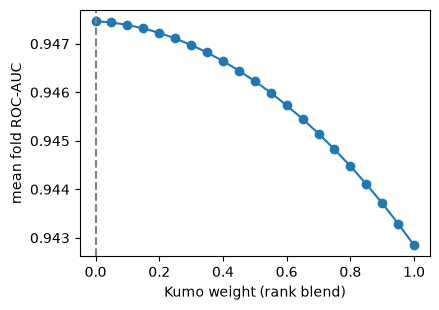

In [ ]:
W_KUMO = 0.0
if "kumo" in full:
    ws = np.linspace(0, 1, 21)
    blend_auc = [np.mean([scores(g[TARGET].to_numpy(), (1 - w) * R.loc[g.index, "lgb_optuna"]
                                 + w * R.loc[g.index, "kumo"])["ROC_AUC"] for _, g in full.groupby("fold")])
                 for w in ws]
    W_KUMO = float(ws[int(np.argmax(blend_auc))])
    plt.figure(figsize=(4.5, 3.2)); plt.plot(ws, blend_auc, "o-")
    plt.axvline(W_KUMO, ls="--", c="grey"); plt.xlabel("Kumo weight (rank blend)"); plt.ylabel("mean fold ROC-AUC")
    plt.tight_layout(); plt.savefig(RES / "blend.png", dpi=150)
    print(f"best weight {W_KUMO:.2f}: AUC {max(blend_auc):.5f} vs LightGBM alone {blend_auc[0]:.5f}")
    R["blend"] = (1 - W_KUMO) * R.lgb_optuna + W_KUMO * R.kumo

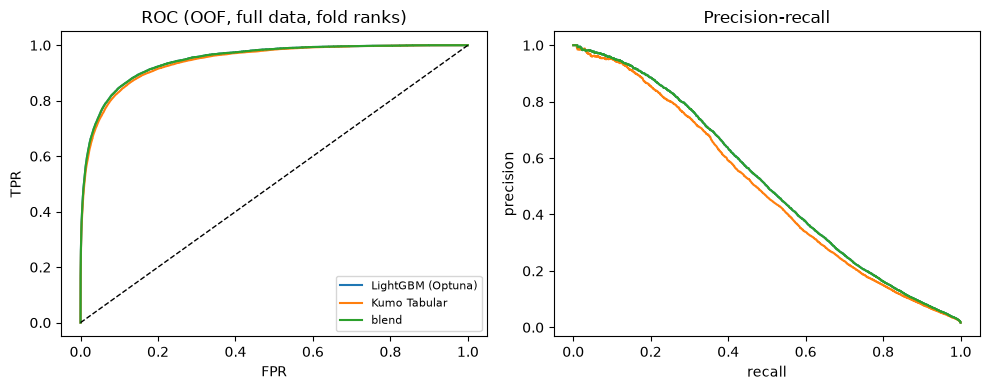

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for m in R.columns:
    fpr, tpr, _ = roc_curve(y, R[m]); ax[0].plot(fpr, tpr, label=NAMES.get(m, m))
    pr, rc, _ = precision_recall_curve(y, R[m]); ax[1].plot(rc, pr, label=NAMES.get(m, m))
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(xlabel="FPR", ylabel="TPR", title="ROC (OOF, full data, fold ranks)")
ax[1].set(xlabel="recall", ylabel="precision", title="Precision-recall")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(RES / "roc_pr.png", dpi=150)

## 5 · Calibration (natural fraud rate)

LightGBM is over-confident partly by design: Optuna picked `scale_pos_weight` > 1, which inflates probabilities. Irrelevant for AUC, relevant if you need real probabilities.

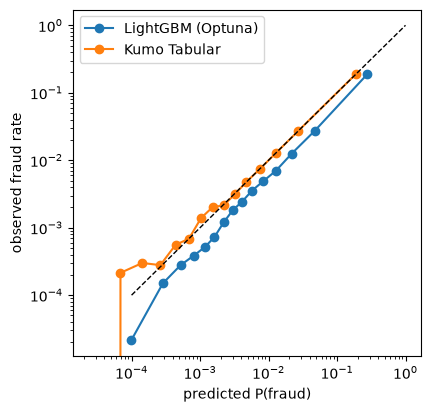

In [ ]:
plt.figure(figsize=(4.5, 4.5))
for m in [c for c in ("lgb_optuna", "kumo") if c in full]:
    pr, ob = reliability(y, full[m].to_numpy(), n_bins=15)
    plt.loglog(pr, ob, "o-", label=NAMES[m])
lim = [1e-4, 1]; plt.plot(lim, lim, "k--", lw=1)
plt.xlabel("predicted P(fraud)"); plt.ylabel("observed fraud rate"); plt.legend()
plt.savefig(RES / "calibration.png", dpi=150, bbox_inches="tight")

## 6 · What Optuna picked

In [ ]:
P = pd.DataFrame(params).T
keep = ["cv_auc", "learning_rate", "num_leaves", "max_depth", "min_child_samples",
        "feature_fraction", "lambda_l2", "scale_pos_weight"]
P[[c for c in keep if c in P]].astype(float).round(4)

,cv_auc,learning_rate,num_leaves,max_depth,min_child_samples,feature_fraction,lambda_l2,scale_pos_weight
n1000_fold0,0.9774,0.0465,17.0,6.0,38.0,0.4951,0.0678,3.4524
n1000_fold1,0.9387,0.0222,12.0,9.0,30.0,0.4150,0.1133,1.7326
n1000_fold2,0.9528,0.0249,38.0,10.0,20.0,0.4527,0.0068,2.0158
n1000_fold3,0.9358,0.0353,13.0,7.0,27.0,0.3915,0.0011,1.9847
n1000_fold4,0.9469,0.0397,30.0,3.0,86.0,0.9848,0.0575,4.5644
n4000_fold0,0.9471,0.0513,16.0,5.0,139.0,0.9709,5.8075,1.9421
n4000_fold1,0.9189,0.0455,43.0,4.0,94.0,0.7917,0.0016,2.7666
n4000_fold2,0.9349,0.0111,21.0,8.0,37.0,0.6027,0.5683,7.2651
n4000_fold3,0.9530,0.0535,66.0,6.0,189.0,0.7719,0.0015,5.2100
n4000_fold4,0.9538,0.0266,120.0,6.0,286.0,0.7603,0.0132,7.9620


## Kaggle submission

In [ ]:
# Average fold models on ranks (their probability scales differ, see section 4).
parts = [pd.read_csv(p) for p in sorted((RES / "oof" / "parts").glob("full_fold*_test.csv.gz"))]
test_ids = pd.read_csv(RES / "test" / "full.csv.gz")[ID]
avg_rank = lambda m: np.mean([p[m].rank(pct=True) for p in parts], axis=0)
subs = {"lgb": avg_rank("lgb_optuna")}
if "kumo" in parts[0]:
    subs["kumo"] = avg_rank("kumo")
    if W_KUMO > 0:
        subs["blend"] = (1 - W_KUMO) * subs["lgb"] + W_KUMO * subs["kumo"]
for name, p in subs.items():
    pd.DataFrame({ID: test_ids, TARGET: p}).to_csv(RES / f"submission_{name}.csv", index=False)
list(subs)

['lgb', 'kumo']

## Takeaways

- **Same data, small N: Kumo wins.** With 1k labeled rows Kumo reaches 0.910 AUC vs. 0.885 for Optuna-tuned LightGBM. Up to 16k rows it is better in all 5 folds; the gap shrinks from +0.025 (1k) to +0.005 (16k).
- **At 64k rows it's a tie.** Kumo 0.943 vs. 0.942, ahead in 3 of 5 folds, not significant (p = 0.13). Once LightGBM has enough rows, the pretrained knowledge stops making a difference.
- **The other metrics agree.** PR-AUC and recall at 1 % false positives favour Kumo at every size, and its log loss is lower everywhere, so its probabilities are usable as they are.
- **Tuning LightGBM matters.** Optuna adds 0.01–0.02 AUC over the defaults. Comparing Kumo against an untuned model would have made it look better than it is.
- **Logistic regression is surprisingly close** to tuned LightGBM at every size. The data is synthetic and linear, so probably not really comparable to real fraud data.
- **Kumo's context matters.** At 16k rows, raising the fraud share in the context from 1.7 % to 25 % lifts Kumo from 0.940 to 0.945.
- **Cost:** Kumo needs 50–400 s per fold on the GPU, LightGBM including Optuna 22–200 s. So Kumo saves effort, not compute.

It would be interesting to give Kumo full training data as context and use `kumo-large` but i only have access to trash GPUs. 